# We compare two AI models:
- Non-private model: Learns without adding privacy noise.
- Private model: Learns using clipped updates and added random noise.
Purpose: To check how privacy protection affects the model's ability to detect network attacks.

In [1]:
from pathlib import Path
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch_geometric.nn import GCNConv
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix
)

BASE = Path("D:/adaptive_federated_gnn")
GRAPH_PATH = BASE / "data/processed/edge_graph.pt"
DAY10_PATH = BASE / "outputs/day10/federated_clients.pt"
DAY17 = BASE / "outputs/day17"
OUT = BASE / "outputs/day18"
OUT.mkdir(parents=True, exist_ok=True)

graph = torch.load(GRAPH_PATH, map_location="cpu", weights_only=False)
day10_clients = torch.load(
    DAY10_PATH, map_location="cpu", weights_only=False
)

edge_index = graph["edge_index"].long()
feature_key = "edge_attr" if "edge_attr" in graph else "edge_features"
label_key = "edge_label" if "edge_label" in graph else "edge_labels"

edge_features = graph[feature_key].float()
edge_labels = graph[label_key].long().view(-1)

num_nodes = int(edge_index.max().item()) + 1
feature_size = edge_features.shape[1]

# Load the shared starting model and three Day 17 client models.
shared_state = torch.load(
    DAY17 / "shared_initial_model.pt",
    map_location="cpu",
    weights_only=True
)

client_states = {
    name: torch.load(
        DAY17 / f"{name}_retrained_model.pt",
        map_location="cpu",
        weights_only=True
    )
    for name in ["client_1", "client_2", "client_3"]
}

private_state = torch.load(
    DAY17 / "private_global_model.pt",
    map_location="cpu",
    weights_only=True
)

print("Graph:", tuple(edge_features.shape))
print("Clients loaded:", list(client_states.keys()))
print("Private global model loaded.")

c:\Users\daksh\anaconda3\envs\adaptive_gnn\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Graph: (286095, 67)
Clients loaded: ['client_1', 'client_2', 'client_3']
Private global model loaded.


In [2]:
class EdgeGCN(nn.Module):
    def __init__(self, num_nodes, edge_feature_size,
                 embedding_size=16, hidden_size=32):
        super().__init__()

        self.node_embeddings = nn.Embedding(num_nodes, embedding_size)
        self.conv1 = GCNConv(embedding_size, hidden_size)
        self.conv2 = GCNConv(hidden_size, hidden_size)

        self.classifier = nn.Sequential(
            nn.Linear(hidden_size * 2 + edge_feature_size, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 2)
        )

    def forward(self, edge_index, edge_features):
        node_ids = torch.arange(
            self.node_embeddings.num_embeddings,
            device=edge_index.device
        )
        x = self.node_embeddings(node_ids)
        x = F.relu(self.conv1(x, edge_index))
        x = F.relu(self.conv2(x, edge_index))

        source = x[edge_index[0]]
        destination = x[edge_index[1]]
        combined = torch.cat(
            [source, destination, edge_features], dim=1
        )
        return self.classifier(combined)

print("Model architecture ready.")

Model architecture ready.


In [4]:
# Load Non-IID client data from the correct folder
DAY16 = BASE / "outputs/day16"

day17_clients = torch.load(
    DAY16 / "non_iid_clients.pt",
    map_location="cpu",
    weights_only=False
)

client_sizes = {
    name: len(day17_clients[name]["edge_labels"])
    for name in client_states
}

total_size = sum(client_sizes.values())

weights = {
    name: size / total_size
    for name, size in client_sizes.items()
}

baseline_state = {}

for key, base_tensor in shared_state.items():
    combined_delta = torch.zeros_like(
        base_tensor, dtype=torch.float32
    )

    for name, local_state in client_states.items():
        raw_delta = (
            local_state[key].float() - base_tensor.float()
        )
        combined_delta += weights[name] * raw_delta

    baseline_state[key] = base_tensor.float() + combined_delta

baseline_path = OUT / "non_private_global_model.pt"
torch.save(baseline_state, baseline_path)

print("Non-private model saved:", baseline_path)
print("Client weights:", weights)

Non-private model saved: D:\adaptive_federated_gnn\outputs\day18\non_private_global_model.pt
Client weights: {'client_1': 0.3333366622392218, 'client_2': 0.33333166888038906, 'client_3': 0.33333166888038906}


In [5]:
# Recover the original Day 10 train/test split.
train_indices = np.unique(np.concatenate([
    data["local_edge_indices"].cpu().numpy()
    if torch.is_tensor(data["local_edge_indices"])
    else np.asarray(data["local_edge_indices"])
    for data in day10_clients.values()
])).astype(np.int64)

train_mask = np.zeros(len(edge_labels), dtype=bool)
train_mask[train_indices] = True
test_indices = np.flatnonzero(~train_mask)

if len(test_indices) == 0:
    raise RuntimeError("No held-out test edges found.")

test_idx = torch.tensor(test_indices, dtype=torch.long)
test_y = edge_labels[test_idx].numpy()

attack_label = int(torch.unique(edge_labels, return_counts=True)[0][-1])

models = {}

for name, state in [
    ("Non-private FedAvg", baseline_state),
    ("Private FedAvg", private_state)
]:
    model = EdgeGCN(num_nodes, feature_size)
    model.load_state_dict(state)
    model.eval()
    models[name] = model

results = []
predictions_by_model = {}

for name, model in models.items():
    with torch.no_grad():
        logits = model(edge_index, edge_features)[test_idx]
        predictions = logits.argmax(dim=1).numpy()

    predictions_by_model[name] = predictions

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(test_y, predictions),
        "Precision": precision_score(
            test_y, predictions, pos_label=attack_label,
            zero_division=0
        ),
        "Recall": recall_score(
            test_y, predictions, pos_label=attack_label,
            zero_division=0
        ),
        "F1 Score": f1_score(
            test_y, predictions, pos_label=attack_label,
            zero_division=0
        )
    })

comparison = pd.DataFrame(results)
display(comparison)

comparison.to_csv(
    OUT / "private_vs_nonprivate_metrics.csv",
    index=False
)

print("Comparison metrics saved.")

,Model,Accuracy,Precision,Recall,F1 Score
0,Non-private FedAvg,0.413275,0.007968,0.000462,0.000873
1,Private FedAvg,0.572790,0.565121,0.999475,0.722007


Comparison metrics saved.


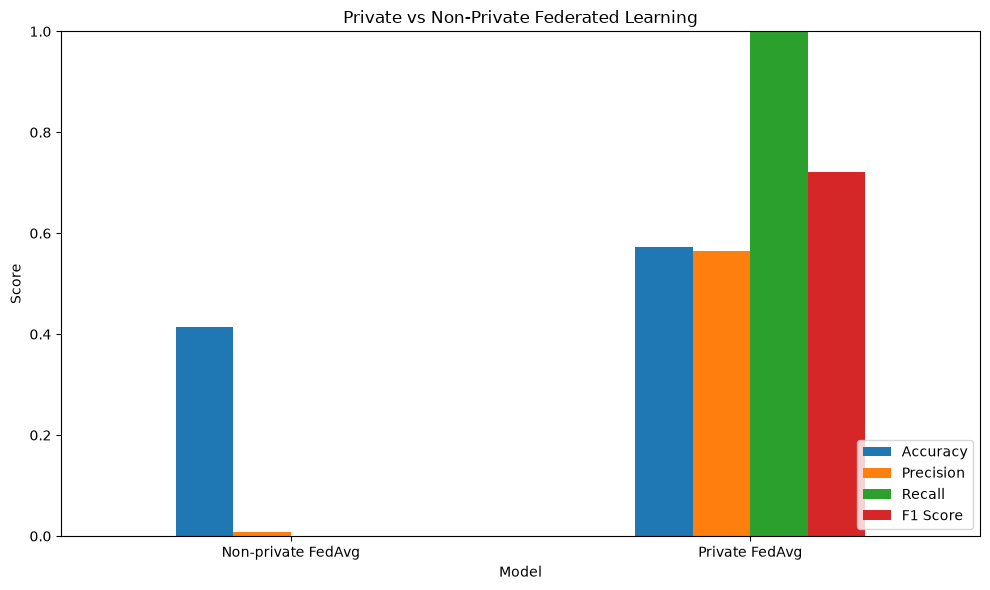

In [6]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1 Score"]

plot_df = comparison.set_index("Model")[metrics_to_plot]
plot_df.plot(kind="bar", figsize=(10, 6), ylim=(0, 1))

plt.title("Private vs Non-Private Federated Learning")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig(OUT / "private_vs_nonprivate_comparison.png", dpi=150)
plt.show()

In [7]:
for name, predictions in predictions_by_model.items():
    cm = confusion_matrix(test_y, predictions, labels=[0, 1])
    safe_name = name.lower().replace(" ", "_")

    pd.DataFrame(
        cm,
        index=["Actual 0", "Actual 1"],
        columns=["Predicted 0", "Predicted 1"]
    ).to_csv(OUT / f"{safe_name}_confusion_matrix.csv")

print("DAY 18 OUTPUT FILES")

for path in sorted(OUT.iterdir()):
    print(path.name)

print("\nFinal comparison:")
display(pd.read_csv(OUT / "private_vs_nonprivate_metrics.csv"))

DAY 18 OUTPUT FILES
non-private_fedavg_confusion_matrix.csv
non_private_global_model.pt
private_fedavg_confusion_matrix.csv
private_vs_nonprivate_comparison.png
private_vs_nonprivate_metrics.csv

Final comparison:


,Model,Accuracy,Precision,Recall,F1 Score
0,Non-private FedAvg,0.413275,0.007968,0.000462,0.000873
1,Private FedAvg,0.572790,0.565121,0.999475,0.722007
